# Phân tích doanh số và phân khúc khách hàng – Olist (Brazil)

Notebook đọc kết quả truy vấn SQL (`outputs/tables/`) do `src/02_run_sql.py` tạo ra, vẽ biểu đồ và rút ra nhận định.
Giai đoạn phân tích: **01/2017 – 08/2018**, chỉ tính **đơn đã giao**. Đơn vị tiền: **BRL (R$)**.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
T, F = ROOT / "outputs" / "tables", ROOT / "outputs" / "figures"
F.mkdir(parents=True, exist_ok=True)

# Màu: xanh cho chuỗi chính, cam cho chuỗi so sánh, xám cho phần nền
BLUE, ORANGE, GREY, INK, INK2 = "#2a78d6", "#eb6834", "#c9c8c3", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": "#ebeae6", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "semibold", "axes.titlesize": 12, "axes.titlelocation": "left",
})
brl = mtick.FuncFormatter(lambda x, _: f"R$ {x/1e6:.1f} tr" if x >= 1e6 else f"R$ {x/1e3:.0f} N")

## 1. Tổng quan

In [2]:
kpi = pd.read_csv(T / "01_kpi_overview.csv").iloc[0]
log = pd.read_csv(T / "data_quality_log.csv")
print(f"Số đơn đã giao : {kpi.so_don:,.0f}")
print(f"Số khách hàng  : {kpi.so_khach:,.0f}")
print(f"Doanh thu      : R$ {kpi.doanh_thu:,.2f}")
print(f"Giá trị đơn TB : R$ {kpi.gia_tri_don_tb:,.2f}")
log

Số đơn đã giao : 96,203
Số khách hàng  : 93,096
Doanh thu      : R$ 15,371,741.09
Giá trị đơn TB : R$ 159.78


,bang,van_de,so_dong
0,orders,Thiếu ngày giao cho khách (tất cả trạng thái),2965
1,orders,Trạng thái 'delivered' nhưng thiếu ngày giao (...,8
2,reviews,Đơn có nhiều đánh giá – giữ đánh giá mới nhất,559
3,products,Sửa tên cột viết sai chính tả ('lenght' -> 'le...,2
4,products,Thiếu danh mục sản phẩm -> gán 'unknown',610
5,products,Danh mục chưa có bản dịch tiếng Anh -> dịch th...,13
6,orders,Bản ghi trùng theo khóa ['order_id'],0
7,customers,Bản ghi trùng theo khóa ['customer_id'],0
8,items,"Bản ghi trùng theo khóa ['order_id', 'order_it...",0
9,payments,"Bản ghi trùng theo khóa ['order_id', 'payment_...",0


## 2. Doanh thu theo tháng

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


Doanh thu T1–T8/2017: R$ 3,472,704 | T1–T8/2018: R$ 8,450,535 | Tăng trưởng: 143.3%


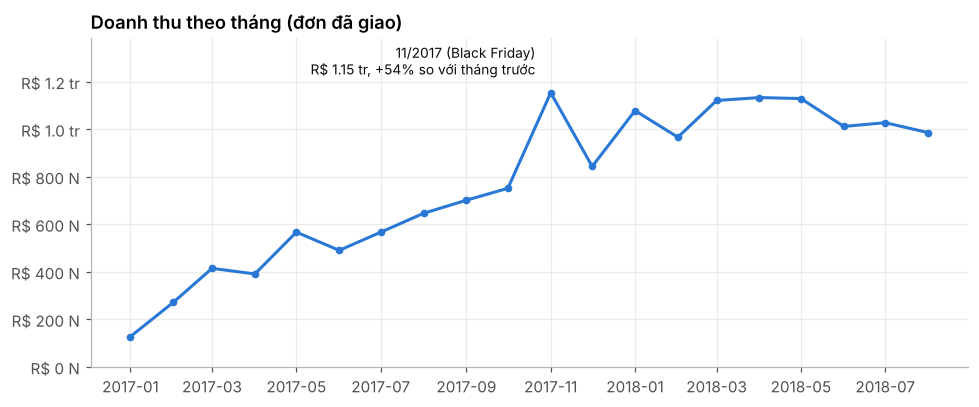

In [3]:
m = pd.read_csv(T / "02_monthly_revenue.csv")
m["thang_dt"] = pd.to_datetime(m["thang"])

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(m["thang_dt"], m["doanh_thu"], color=BLUE, lw=2, marker="o", ms=4)
peak = m.loc[m["doanh_thu"].idxmax()]
ax.annotate(f"11/2017 (Black Friday)\nR$ {peak.doanh_thu/1e6:.2f} tr, +{peak.tang_truong_mom_pct:.0f}% so với tháng trước",
            xy=(peak.thang_dt, peak.doanh_thu), xytext=(-10, 12), textcoords="offset points",
            ha="right", color=INK, fontsize=9)
ax.yaxis.set_major_formatter(brl)
ax.set_title("Doanh thu theo tháng (đơn đã giao)")
ax.set_xlabel(""); ax.set_ylim(0, m["doanh_thu"].max() * 1.2)
fig.tight_layout(); fig.savefig(F / "01_monthly_revenue.png")

# So sánh cùng kỳ 8 tháng đầu năm
h17 = m[m.thang.between("2017-01", "2017-08")].doanh_thu.sum()
h18 = m[m.thang.between("2018-01", "2018-08")].doanh_thu.sum()
print(f"Doanh thu T1–T8/2017: R$ {h17:,.0f} | T1–T8/2018: R$ {h18:,.0f} | Tăng trưởng: {100*(h18/h17-1):.1f}%")

## 3. Danh mục sản phẩm

Có 74 danh mục; top 3 chiếm 25.9% doanh thu hàng; 18 danh mục đầu tạo ra 80% doanh thu hàng.


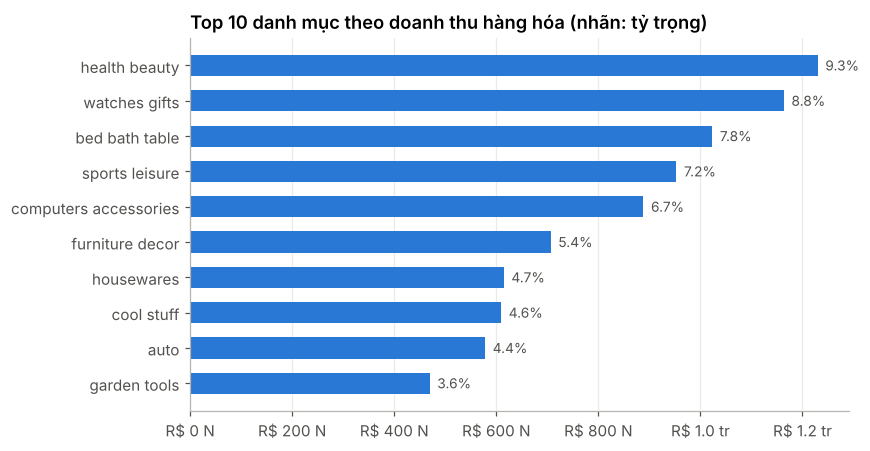

In [4]:
c = pd.read_csv(T / "03_category_revenue.csv")
top = c.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(top["danh_muc"], top["doanh_thu_hang"], color=BLUE, height=0.6)
for y, (v, p) in enumerate(zip(top["doanh_thu_hang"], top["ty_trong_pct"])):
    ax.text(v, y, f"  {p:.1f}%", va="center", fontsize=9, color=INK2)
ax.xaxis.set_major_formatter(brl); ax.grid(axis="y", visible=False)
ax.set_title("Top 10 danh mục theo doanh thu hàng hóa (nhãn: tỷ trọng)")
fig.tight_layout(); fig.savefig(F / "02_top_categories.png")

n_cat = len(c); n80 = (c["ty_trong_luy_ke_pct"] < 80).sum() + 1
print(f"Có {n_cat} danh mục; top 3 chiếm {c.head(3).ty_trong_pct.sum():.1f}% doanh thu hàng; "
      f"{n80} danh mục đầu tạo ra 80% doanh thu hàng.")

## 4. Giao hàng trễ và đánh giá của khách

,tinh_trang_giao,so_don,ty_le_pct,so_ngay_giao_tb,diem_danh_gia_tb,ty_le_danh_gia_1_2_sao_pct
0,Đúng hạn,89672,93.21,11.0,4.28,9.5
1,Giao trễ,6531,6.79,33.9,2.26,62.9


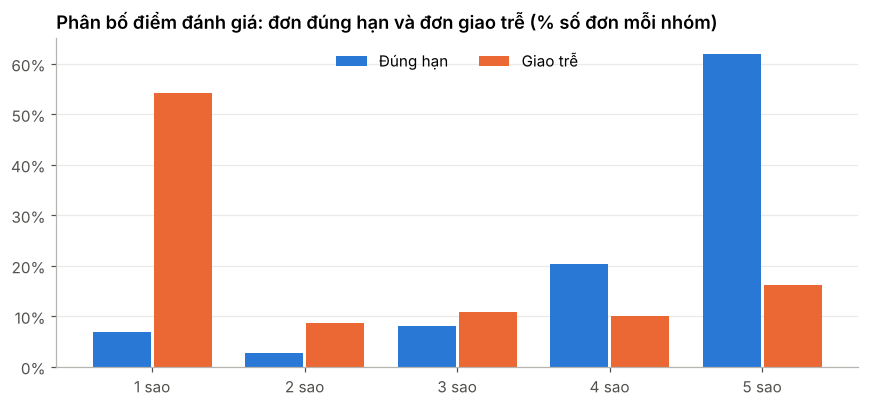

In [5]:
d = pd.read_csv(T / "04_delivery_vs_review.csv")
display(d)

# Phân bố số sao theo tình trạng giao hàng (tính trực tiếp từ CSDL)
import sqlite3
with sqlite3.connect(ROOT / "data" / "olist.db") as con:
    dist = pd.read_sql_query("""
        SELECT CASE o.is_late WHEN 1 THEN 'Giao trễ' ELSE 'Đúng hạn' END AS tinh_trang,
               r.review_score AS sao, COUNT(*) AS so_don
        FROM orders o JOIN reviews r ON r.order_id = o.order_id
        WHERE o.is_delivered = 1 AND o.purchase_month BETWEEN '2017-01' AND '2018-08'
        GROUP BY 1, 2""", con)
dist["pct"] = dist["so_don"] / dist.groupby("tinh_trang")["so_don"].transform("sum") * 100
pv = dist.pivot(index="sao", columns="tinh_trang", values="pct")

fig, ax = plt.subplots(figsize=(8, 3.8))
w = 0.38
ax.bar(pv.index - w/2 - 0.01, pv["Đúng hạn"], w, color=BLUE, label="Đúng hạn")
ax.bar(pv.index + w/2 + 0.01, pv["Giao trễ"], w, color=ORANGE, label="Giao trễ")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xticks(pv.index, [f"{s} sao" for s in pv.index]); ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="upper center", ncol=2)
ax.set_title("Phân bố điểm đánh giá: đơn đúng hạn và đơn giao trễ (% số đơn mỗi nhóm)")
fig.tight_layout(); fig.savefig(F / "03_late_vs_review.png")

## 5. Phân khúc khách hàng RFM

,phan_khuc,so_khach,ty_le_khach_pct,doanh_thu,ty_trong_doanh_thu_pct,chi_tieu_tb,recency_tb_ngay
0,Khách mới giá trị cao,14408,15.5,4351147.69,28.3,302.00,92.0
1,Giá trị cao có nguy cơ rời bỏ,13698,14.7,4211810.93,27.4,307.48,392.0
2,Cần chăm sóc,18017,19.4,2732338.86,17.8,151.65,220.0
3,Ngủ đông,22551,24.2,1637430.21,10.7,72.61,394.0
4,Khách mới giá trị thấp,21633,23.2,1578480.21,10.3,72.97,90.0
5,Khách mua lặp lại,2789,3.0,860533.19,5.6,308.55,220.0


Tỷ lệ khách chỉ mua 1 lần: 97.0%


Hai nhóm giá trị cao: 30.2% số khách, 55.7% doanh thu


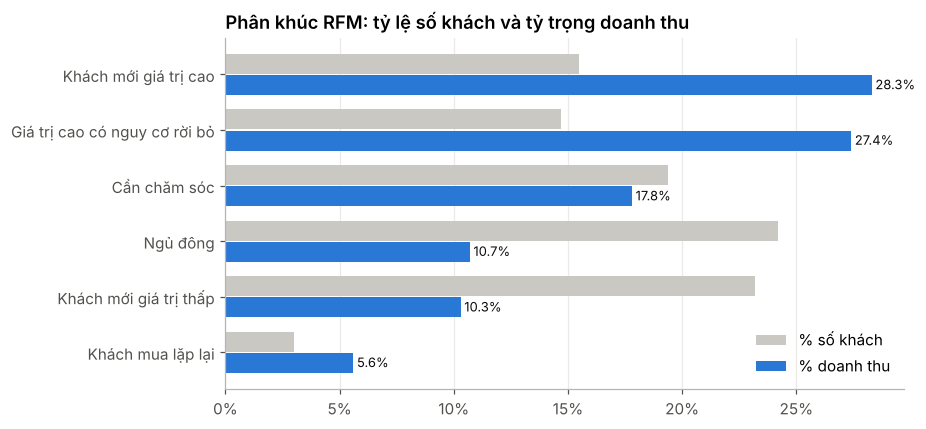

In [6]:
rfm = pd.read_csv(T / "05_rfm.csv")
seg = pd.read_csv(T / "06_rfm_segment_summary.csv")
display(seg)
print(f"Tỷ lệ khách chỉ mua 1 lần: {100*(rfm.frequency == 1).mean():.1f}%")

s = seg.sort_values("ty_trong_doanh_thu_pct")
fig, ax = plt.subplots(figsize=(8.5, 4))
y = range(len(s)); h = 0.36
ax.barh([i + h/2 + 0.01 for i in y], s["ty_le_khach_pct"], h, color=GREY, label="% số khách")
ax.barh([i - h/2 - 0.01 for i in y], s["ty_trong_doanh_thu_pct"], h, color=BLUE, label="% doanh thu")
for i, (a, b) in enumerate(zip(s["ty_le_khach_pct"], s["ty_trong_doanh_thu_pct"])):
    ax.text(b, i - h/2, f" {b:.1f}%", va="center", fontsize=8.5, color=INK)
ax.set_yticks(list(y), s["phan_khuc"]); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.legend(frameon=False, loc="lower right")
ax.set_title("Phân khúc RFM: tỷ lệ số khách và tỷ trọng doanh thu")
fig.tight_layout(); fig.savefig(F / "04_rfm_segments.png")

hv = seg[seg.phan_khuc.isin(["Khách mới giá trị cao", "Giá trị cao có nguy cơ rời bỏ"])]
print(f"Hai nhóm giá trị cao: {hv.ty_le_khach_pct.sum():.1f}% số khách, {hv.ty_trong_doanh_thu_pct.sum():.1f}% doanh thu")

## 6. Nhận định chính

Các con số dưới đây lấy từ kết quả ở trên (xem README để có bản tóm tắt).

1. **Khách hàng gần như không quay lại**: ~97% khách chỉ mua 1 lần trong giai đoạn → ưu tiên chương trình giữ chân (email sau mua, ưu đãi đơn thứ hai).
2. **Giao trễ là nguyên nhân lớn của đánh giá xấu**: điểm TB giảm từ 4,28 xuống 2,26; tỷ lệ đánh giá 1–2 sao tăng từ 9,5% lên 62,9%.
3. **Doanh thu tập trung**: hai nhóm khách giá trị cao chiếm ~30% số khách nhưng ~56% doanh thu; một nửa trong số đó đã lâu không mua (nguy cơ rời bỏ) → nhóm nên ưu tiên tái kích hoạt.
4. **Mùa vụ**: tháng 11/2017 (Black Friday) đạt đỉnh doanh thu, cần chuẩn bị tồn kho và năng lực giao hàng trước mùa cao điểm.